# Angular reduction of Goldstone diagrams

`angularinator.py` writes the numerator of a Goldstone diagram (or a sum of them, or all the time orderings of a Feynman diagram) in terms of reduced quantities: the Coulomb integrals $Q^k$ and $W^k = Q^k + P^k$, reduced matrix elements $\langle p\|t\|r\rangle$, $6j$ symbols, phases and factors $[j] = 2j+1$. Conventions are those of the Methods notes (Sec. *Coulomb integrals*):

$$g_{abcd} = \sum_k A^k_{abcd}\,Q^k_{abcd},\qquad \tilde g_{abcd} = g_{abcd} - g_{abdc} = \sum_k A^k_{abcd}\,W^k_{abcd},\qquad
\langle a m_a|t^k_q|b m_b\rangle = (-1)^{j_a-m_a}\begin{pmatrix}j_a&k&j_b\\-m_a&q&m_b\end{pmatrix}\langle a\|t\|b\rangle .$$

In the output a letter stands for its $j$ in phases, $[j]$ factors and $6j$ symbols. Signs and energy denominators are goldstoninator's.

It also writes C++ for ampsci: `.ampsci()` evaluates the reduced form, and `.ampsci_fullmsum()` evaluates the same quantity by brute force over every magnetic quantum number, using only `Coulomb::g_abcd` and `TensorOperator::fullME`. The two functions have the same arguments and return the same value, so each reduction can be checked independently in ampsci.

In [1]:
import goldstoninator as gd
import feynmanator as fd
import angularinator as ang

## Antisymmetrised integrals

goldstoninator accepts $\tilde g_{pqrs}$ (written `\tilde g_{pqrs}`, `\widetilde{g}_{pqrs}` or `g~_pqrs`), which stands for $g_{pqrs} - g_{pqsr}$. It gives the two diagrams, each with its own sign; the exchange diagram always has the opposite sign, so the pair sums to the term with $\tilde g$:

In [2]:
rpa = gd.diagram(r"t_na \tilde g_wavn")
rpa

In [3]:
rpa.equation()

$$\begin{aligned}
&+\frac{t_{na}\,g_{wavn}}{(\varepsilon_a-\varepsilon_n+\omega_t)} \\
&-\frac{t_{na}\,g_{wanv}}{(\varepsilon_a-\varepsilon_n+\omega_t)}
\end{aligned}$$

## The second-order energy

The four Goldstone diagrams of the second-order correlation energy. With $\tilde g$ the result is Eq. (dE-SO-red) of the notes:

In [4]:
de2 = ang.angular([r"g_vamn \tilde g_nmav", r"g_vnab \tilde g_banv"])
de2.equation()

$$\begin{aligned}
&+\sum_{amn}\sum_{k}\frac{1}{[k][v]}\frac{Q^{k}_{vamn}\,W^{k}_{nmav}}{(\varepsilon_{va}-\varepsilon_{mn})} \\
&+\sum_{nab}\sum_{k}\frac{1}{[k][v]}\frac{Q^{k}_{vnab}\,W^{k}_{banv}}{(\varepsilon_{vn}-\varepsilon_{ab})}
\end{aligned}$$

The same from the four plain diagrams: each pair of diagrams that differ by the exchange of the incoming lines of one Coulomb integral (and have opposite signs) is merged into $W$, at the later integral ($QW$ rather than $WQ$):

In [5]:
gd.grid(["g_vamn g_nmav", "g_vamn g_nmva", "g_vnab g_banv", "g_vnab g_bavn"]).angular().equation()

$$\begin{aligned}
&+\sum_{amn}\sum_{k}\frac{1}{[k][v]}\frac{Q^{k}_{vamn}\,W^{k}_{nmav}}{(\varepsilon_{va}-\varepsilon_{mn})} \\
&+\sum_{nab}\sum_{k}\frac{1}{[k][v]}\frac{Q^{k}_{vnab}\,W^{k}_{banv}}{(\varepsilon_{vn}-\varepsilon_{ab})}
\end{aligned}$$

With one valence line and no external field (as here) the result is the $m$-independent value, averaged over $m$: $\frac{1}{[j_v]}\sum_m\langle w\,m|X|v\,m\rangle$ (zero unless $j_w = j_v$). For an off-diagonal element ($v \to w$) a $\delta_{j_v j_w}$ appears where the reduction needs it:

In [6]:
ang.angular([r"g_vamn \tilde g_nmaw", r"g_vnab \tilde g_banw"]).equation()

$$\begin{aligned}
&+\sum_{amn}\sum_{k}\frac{\delta_{j_v j_w}}{[k][v]}\frac{Q^{k}_{vamn}\,W^{k}_{nmaw}}{(\varepsilon_{wa}-\varepsilon_{mn})} \\
&+\sum_{nab}\sum_{k}\frac{\delta_{j_v j_w}}{[k][v]}\frac{Q^{k}_{vnab}\,W^{k}_{banw}}{(\varepsilon_{vn}-\varepsilon_{ab})}
\end{aligned}$$

## An external field: reduced matrix elements

With one external field (any one-body vertex, here $t$ of rank $k$) the result is the reduced matrix element $\langle w\|X\|v\rangle$. First-order core polarisation (RPA):

In [7]:
ang.angular([r"t_na \tilde g_wavn", r"t_an \tilde g_wnva"]).equation()

$$\begin{aligned}
&+\sum_{na}\frac{(-1)^{k+w-n}}{[k]}\frac{W^{k}_{wavn}\,\langle n\|t\|a\rangle}{(\varepsilon_a-\varepsilon_n+\omega_t)} \\
&+\sum_{an}\frac{(-1)^{k+w-a}}{[k]}\frac{W^{k}_{wnva}\,\langle a\|t\|n\rangle}{(\varepsilon_a-\varepsilon_n-\omega_t)}
\end{aligned}$$

The first term is the Methods formula; the second appears as $(-1)^{k+w-a}$, equal to the notes' $(-1)^{k+w-n}(-1)^{a-n}$ (since $(-1)^{2j}=-1$ for half-integer $j$).

A one-body operator that is a scalar (rank 0, not an external field) is declared with `ranks={'h': 0}`; then the result is again the $m$-averaged value (`omega=False`: a static potential absorbs no energy). `ranks={'t': 'K'}` names the rank of a field.

In [8]:
ang.angular(["h_na g_wavn", "g_wnva h_an"], ranks={"h": 0}, omega=False).equation()

$$\begin{aligned}
&+\sum_{na}\frac{(-1)^{w-n}\delta_{j_w j_v}\delta_{j_n j_a}}{\sqrt{[w]}}\frac{Q^{0}_{wavn}\,\langle n\|h\|a\rangle}{(\varepsilon_a-\varepsilon_n)} \\
&+\sum_{na}\frac{(-1)^{w-n}\delta_{j_w j_v}\delta_{j_n j_a}}{\sqrt{[w]}}\frac{Q^{0}_{wnva}\,\langle a\|h\|n\rangle}{(\varepsilon_{va}-\varepsilon_{wn})}
\end{aligned}$$

## Two valence lines

For an effective two-body interaction (two valence letters in, two out) the result is $S^k$ in $X = \sum_k A^k_{xyvw}S^k_{xyvw}$, the incoming $v, w$ paired with the outgoing $x, y$ in the order of the valence letters (as in goldstoninator). Ladder diagrams of the CI $\Sigma^2$:

In [9]:
ang.angular(["g_mnvw g_xymn", "g_abvw g_xyab"]).equation()

$$\begin{aligned}
&+\sum_{mn}\sum_{\mu}\sum_{\lambda}(-1)^{v-w+x-y+m-n}[k]\begin{Bmatrix}v&x&k\\\lambda&\mu&m\end{Bmatrix}\begin{Bmatrix}w&y&k\\\lambda&\mu&n\end{Bmatrix}\frac{Q^{\mu}_{mnvw}\,Q^{\lambda}_{xymn}}{(\varepsilon_{vw}-\varepsilon_{mn})} \\
&-\sum_{ab}\sum_{\mu}\sum_{\lambda}(-1)^{v-w+x-y+a-b}[k]\begin{Bmatrix}v&x&k\\\lambda&\mu&a\end{Bmatrix}\begin{Bmatrix}w&y&k\\\lambda&\mu&b\end{Bmatrix}\frac{Q^{\mu}_{abvw}\,Q^{\lambda}_{xyab}}{(\varepsilon_{xy}-\varepsilon_{ab})}
\end{aligned}$$

In [10]:
ang.angular([r"g_vnxa \tilde g_awny", "g_vnax g_awny", "g_vnay g_awxn"]).equation()

$$\begin{aligned}
&+\sum_{na}\frac{(-1)^{k}}{[k]}\frac{Q^{k}_{vnxa}\,W^{k}_{awny}}{(\varepsilon_{xa}-\varepsilon_{vn})} \\
&+\sum_{na}\sum_{\mu}(-1)^{k}\begin{Bmatrix}x&v&k\\a&n&\mu\end{Bmatrix}\frac{Q^{\mu}_{vnax}\,Q^{k}_{awny}}{(\varepsilon_{xa}-\varepsilon_{vn})} \\
&-\sum_{na}\sum_{\mu}\sum_{\lambda}(-1)^{\mu+\lambda+k+x-y+v-w+n-a}[k]\begin{Bmatrix}x&v&k\\\mu&\lambda&a\end{Bmatrix}\begin{Bmatrix}y&w&k\\\lambda&\mu&n\end{Bmatrix}\frac{Q^{\mu}_{vnay}\,Q^{\lambda}_{awxn}}{(\varepsilon_{ya}-\varepsilon_{vn})}
\end{aligned}$$

## Third order, and loops

Higher orders work the same way; diagrams with a Coulomb loop on one vertex (the Hartree and exchange terms) force the multipolarity where the angular algebra requires it:

In [11]:
ang.angular([r"g_vbms g_asnb \tilde g_mnva", "g_vava", "g_vaav"]).equation()

$$\begin{aligned}
&+\sum_{bmsan}\sum_{k}\frac{(-1)^{k}}{[k]^{2}[v]}\frac{Q^{k}_{vbms}\,Q^{k}_{asnb}\,W^{k}_{mnva}}{(\varepsilon_{va}-\varepsilon_{mn})(\varepsilon_{vb}-\varepsilon_{ms})} \\
&+\sum_{a}\frac{(-1)^{v-a}\sqrt{[a]}}{\sqrt{[v]}}W^{0}_{vava}
\end{aligned}$$

In [12]:
ang.angular(["g_vbrs g_asnb t_rm g_mnwa"]).equation()

$$\begin{aligned}
&-\sum_{brsanm}\sum_{\mu}\frac{(-1)^{k+v-r}}{[\mu]^{2}}\begin{Bmatrix}w&v&k\\r&m&\mu\end{Bmatrix}\frac{Q^{\mu}_{vbrs}\,Q^{\mu}_{asnb}\,Q^{\mu}_{mnwa}\,\langle r\|t\|m\rangle}{(\varepsilon_{wa}-\varepsilon_{mn})(\varepsilon_{wb}-\varepsilon_{ms})(\varepsilon_{wb}-\varepsilon_{rs}+\omega_t)}
\end{aligned}$$

## Feynman diagrams

A Feynman diagram gives the reduction of all its time orderings:

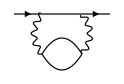

$$\begin{aligned}
&+\sum_{mna}\sum_{k}\frac{\delta_{j_w j_v}}{[k][w]}\frac{Q^{k}_{mnva}\,Q^{k}_{awnm}}{(\varepsilon_{va}-\varepsilon_{mn})} \\
&+\sum_{mba}\sum_{k}\frac{\delta_{j_w j_v}}{[k][w]}\frac{Q^{k}_{mwba}\,Q^{k}_{abvm}}{(\varepsilon_{wm}-\varepsilon_{ab})}
\end{aligned}$$

In [13]:
pol = fd.diagram("v(1) G(1,2) w(2) Q(1,3) PI(3,4) Q(4,2)")
display(pol, pol.angular().equation())

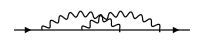

$$\begin{aligned}
&+\sum_{mna}\sum_{\mu}\sum_{\lambda}\frac{\delta_{j_w j_v}}{[w]}\begin{Bmatrix}w&m&\mu\\a&n&\lambda\end{Bmatrix}\frac{Q^{\mu}_{mnva}\,Q^{\lambda}_{awmn}}{(\varepsilon_{va}-\varepsilon_{mn})} \\
&+\sum_{mab}\sum_{\mu}\sum_{\lambda}\frac{\delta_{j_w j_v}}{[w]}\begin{Bmatrix}w&a&\lambda\\m&b&\mu\end{Bmatrix}\frac{Q^{\mu}_{mwab}\,Q^{\lambda}_{abvm}}{(\varepsilon_{wm}-\varepsilon_{ab})}
\end{aligned}$$

In [14]:
ladder = fd.diagram("v(1) G(1,2) G(2,3) G(3,4) w(4) Q(1,3) Q(2,4)")
display(ladder, ladder.angular().equation())

## Structure radiation

The second-order correlation diagrams with the external field on each internal line: six Feynman diagrams, 36 Goldstone diagrams. Their direct and exchange pairs merge into 12 terms, six with $QW$ and six with $WW$ (the shapes of the notes' $T$, $B$, $C$, $D$). This sum agrees with ampsci's `StructureRad::SR` (which implements the formulas of Phys. Rev. A **107**, 052812) to $10^{-13}$, with $\omega = \varepsilon_w-\varepsilon_v$:

In [15]:
SR = [fd.diagram(x) for x in (
    "v(1) G(1,i) t(i) G(i,2) w(2) Q(1,3) PI(3,4) Q(4,2)",
    "v(1) G(1,2) w(2) Q(1,3) G(3,i) t(i) G(i,4) G(4,3) Q(4,2)",
    "v(1) G(1,2) w(2) Q(1,3) G(3,4) G(4,i) t(i) G(i,3) Q(4,2)",
    "v(1) G(1,i) t(i) G(i,2) G(2,3) G(3,4) w(4) Q(1,3) Q(2,4)",
    "v(1) G(1,2) G(2,i) t(i) G(i,3) G(3,4) w(4) Q(1,3) Q(2,4)",
    "v(1) G(1,2) G(2,3) G(3,i) t(i) G(i,4) w(4) Q(1,3) Q(2,4)",
)]
sr = ang.angular(SR)
print(len(sr.terms), "terms")
sr.equation()

12 terms


$$\begin{aligned}
&+\sum_{mnba}\sum_{\mu}\frac{(-1)^{\mu+k+w-a}}{[\mu]}\begin{Bmatrix}v&w&k\\a&m&\mu\end{Bmatrix}\frac{W^{\mu}_{mnvb}\,W^{\mu}_{bwna}\,\langle a\|t\|m\rangle}{(\varepsilon_{vb}-\varepsilon_{mn})(\varepsilon_a-\varepsilon_m-\omega_t)} \\
&-\sum_{mran}\sum_{\mu}\frac{(-1)^{\mu+k+w-n}}{[\mu]}\begin{Bmatrix}v&w&k\\n&m&\mu\end{Bmatrix}\frac{W^{\mu}_{mrva}\,W^{\mu}_{awrn}\,\langle n\|t\|m\rangle}{(\varepsilon_{va}-\varepsilon_{mr})(\varepsilon_{va}-\varepsilon_{nr}+\omega_t)} \\
&-\sum_{nbam}\sum_{\mu}\frac{(-1)^{\mu+k+w-a}}{[\mu]}\begin{Bmatrix}v&w&k\\a&m&\mu\end{Bmatrix}\frac{W^{\mu}_{nwba}\,W^{\mu}_{mbvn}\,\langle a\|t\|m\rangle}{(\varepsilon_{vn}-\varepsilon_{ab}+\omega_t)(\varepsilon_a-\varepsilon_m-\omega_t)} \\
&-\sum_{mcba}\sum_{\mu}\frac{(-1)^{\mu+k+w-b}}{[\mu]}\begin{Bmatrix}v&w&k\\b&a&\mu\end{Bmatrix}\frac{W^{\mu}_{mwcb}\,W^{\mu}_{acvm}\,\langle b\|t\|a\rangle}{(\varepsilon_{vm}-\varepsilon_{bc}+\omega_t)(\varepsilon_{vm}-\varepsilon_{ac})} \\
&+\sum_{manb}\sum_{\mu}\frac{(-1)^{\mu+k+w-m}}{[\mu]}\begin{Bmatrix}v&w&k\\m&a&\mu\end{Bmatrix}\frac{W^{\mu}_{anvb}\,W^{\mu}_{bwnm}\,\langle m\|t\|a\rangle}{(\varepsilon_a-\varepsilon_m+\omega_t)(\varepsilon_{vb}-\varepsilon_{mn}+\omega_t)} \\
&-\sum_{manb}\sum_{\mu}\frac{(-1)^{\mu+k+w-m}}{[\mu]}\begin{Bmatrix}v&w&k\\m&a&\mu\end{Bmatrix}\frac{W^{\mu}_{nwbm}\,W^{\mu}_{abvn}\,\langle m\|t\|a\rangle}{(\varepsilon_a-\varepsilon_m+\omega_t)(\varepsilon_{vn}-\varepsilon_{ab})} \\
&+\sum_{mran}\sum_{\mu}\sum_{\lambda}(-1)^{k+v-m+r-n}\begin{Bmatrix}v&w&k\\\lambda&\mu&m\end{Bmatrix}\begin{Bmatrix}k&a&n\\r&\lambda&\mu\end{Bmatrix}\frac{Q^{\mu}_{mrva}\,W^{\lambda}_{nwrm}\,\langle a\|t\|n\rangle}{(\varepsilon_{va}-\varepsilon_{mr})(\varepsilon_a-\varepsilon_n-\omega_t)} \\
&-\sum_{mnab}\sum_{\mu}\sum_{\lambda}(-1)^{k+v-m+n-b}\begin{Bmatrix}v&w&k\\\lambda&\mu&m\end{Bmatrix}\begin{Bmatrix}k&a&b\\n&\lambda&\mu\end{Bmatrix}\frac{Q^{\mu}_{mnva}\,W^{\lambda}_{bwnm}\,\langle a\|t\|b\rangle}{(\varepsilon_{va}-\varepsilon_{mn})(\varepsilon_{vb}-\varepsilon_{mn}+\omega_t)} \\
&-\sum_{mcab}\sum_{\mu}\sum_{\lambda}(-1)^{k+v-m+c-a}\begin{Bmatrix}v&w&k\\\mu&\lambda&a\end{Bmatrix}\begin{Bmatrix}k&m&b\\c&\lambda&\mu\end{Bmatrix}\frac{Q^{\mu}_{mwca}\,W^{\lambda}_{acvb}\,\langle b\|t\|m\rangle}{(\varepsilon_{vm}-\varepsilon_{ac}+\omega_t)(\varepsilon_b-\varepsilon_m-\omega_t)} \\
&-\sum_{nbam}\sum_{\mu}\sum_{\lambda}(-1)^{k+v-n+b-a}\begin{Bmatrix}v&w&k\\\mu&\lambda&a\end{Bmatrix}\begin{Bmatrix}k&n&m\\b&\lambda&\mu\end{Bmatrix}\frac{Q^{\mu}_{nwba}\,W^{\lambda}_{abvm}\,\langle m\|t\|n\rangle}{(\varepsilon_{vn}-\varepsilon_{ab}+\omega_t)(\varepsilon_{vm}-\varepsilon_{ab})} \\
&+\sum_{namr}\sum_{\mu}\sum_{\lambda}(-1)^{k+v-a+m-r}\begin{Bmatrix}v&w&k\\\lambda&\mu&m\end{Bmatrix}\begin{Bmatrix}k&n&a\\r&\lambda&\mu\end{Bmatrix}\frac{Q^{\mu}_{mrvn}\,W^{\lambda}_{awrm}\,\langle n\|t\|a\rangle}{(\varepsilon_a-\varepsilon_n+\omega_t)(\varepsilon_{va}-\varepsilon_{mr}+\omega_t)} \\
&-\sum_{mbca}\sum_{\mu}\sum_{\lambda}(-1)^{k+v-b+c-a}\begin{Bmatrix}v&w&k\\\mu&\lambda&a\end{Bmatrix}\begin{Bmatrix}k&m&b\\c&\mu&\lambda\end{Bmatrix}\frac{Q^{\mu}_{bwca}\,W^{\lambda}_{acvm}\,\langle m\|t\|b\rangle}{(\varepsilon_b-\varepsilon_m+\omega_t)(\varepsilon_{vm}-\varepsilon_{ac})}
\end{aligned}$$

## Several external fields

With two or more fields the external $m$-dependence cannot be a single $3j$ symbol. By default (`external='m'`) it is written in the chain basis along the valence line, the fields in the order written:

$$\langle w\,m_w|X|v\,m_v\rangle = \sum_{j_1}(-1)^{w-m_w}\begin{pmatrix}w&k_1&j_1\\-m_w&q_1&m_1\end{pmatrix}(-1)^{j_1-m_1}\begin{pmatrix}j_1&k_2&v\\-m_1&q_2&m_v\end{pmatrix}X_{j_1}$$

and the result is $X_{j_1}$ (like $\langle w\|T\|j_1\rangle\langle j_1\|S\|v\rangle$). The C++ functions take the external $2m$ and $2q$ as arguments and return the $m$-resolved value. Here the Feynman diagram with two fields on the valence line and a Coulomb line across them; the angular factor is a single $9j$ symbol:

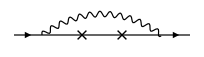

$$\begin{aligned}
\langle w\,m_w|X|v\,m_v\rangle = \sum_{j_1}(-1)^{w-m_w}\begin{pmatrix}w&k_T&j_1\\-m_w&q_{T}&m_1\end{pmatrix}(-1)^{j_1-m_1}\begin{pmatrix}j_1&k_S&v\\-m_1&q_{S}&m_v\end{pmatrix}X_{j_1},\quad X_{j_1}= \\
&+\sum_{man}\sum_{\mu}(-1)^{k_S+k_T+v-m}[j_1]\begin{Bmatrix}k_T&n&m\\j_1&k_S&v\\w&a&\mu\end{Bmatrix}\frac{Q^{\mu}_{mwva}\,\langle n\|T\|m\rangle\,\langle a\|S\|n\rangle}{(\varepsilon_a-\varepsilon_m-\omega_T-\omega_S)(\varepsilon_a-\varepsilon_n-\omega_S)} \\
&-\sum_{mba}\sum_{\mu}(-1)^{k_S+k_T+v-m}[j_1]\begin{Bmatrix}k_T&a&m\\j_1&k_S&v\\w&b&\mu\end{Bmatrix}\frac{Q^{\mu}_{mwvb}\,\langle b\|S\|a\rangle\,\langle a\|T\|m\rangle}{(\varepsilon_b-\varepsilon_m-\omega_S-\omega_T)(\varepsilon_a-\varepsilon_m-\omega_T)} \\
&-\sum_{mab}\sum_{\mu}(-1)^{k_S+k_T+v-a}[j_1]\begin{Bmatrix}k_T&m&a\\j_1&k_S&v\\w&b&\mu\end{Bmatrix}\frac{Q^{\mu}_{awvb}\,\langle m\|T\|a\rangle\,\langle b\|S\|m\rangle}{(\varepsilon_a-\varepsilon_m+\omega_T)(\varepsilon_b-\varepsilon_m-\omega_S)} \\
&+\sum_{man}\sum_{\mu}(-1)^{k_S+k_T+v-a}[j_1]\begin{Bmatrix}k_T&m&a\\j_1&k_S&v\\w&n&\mu\end{Bmatrix}\frac{Q^{\mu}_{awvn}\,\langle m\|T\|a\rangle\,\langle n\|S\|m\rangle}{(\varepsilon_a-\varepsilon_m+\omega_T)(\varepsilon_a-\varepsilon_n+\omega_T+\omega_S)} \\
&+\sum_{nam}\sum_{\mu}(-1)^{k_S+k_T+v-m}[j_1]\begin{Bmatrix}k_T&a&m\\j_1&k_S&v\\w&n&\mu\end{Bmatrix}\frac{Q^{\mu}_{mwvn}\,\langle n\|S\|a\rangle\,\langle a\|T\|m\rangle}{(\varepsilon_a-\varepsilon_n+\omega_S)(\varepsilon_a-\varepsilon_m-\omega_T)} \\
&-\sum_{mba}\sum_{\mu}(-1)^{k_S+k_T+v-a}[j_1]\begin{Bmatrix}k_T&b&a\\j_1&k_S&v\\w&m&\mu\end{Bmatrix}\frac{Q^{\mu}_{awvm}\,\langle m\|S\|b\rangle\,\langle b\|T\|a\rangle}{(\varepsilon_b-\varepsilon_m+\omega_S)(\varepsilon_a-\varepsilon_m+\omega_S+\omega_T)}
\end{aligned}$$

In [16]:
ts = fd.diagram("v(1) G(1,i) T(i)G(i,j)S(j)G(j,2) w(2) Q(1,2)")
display(ts, ts.angular().equation())

`external='coupled'` couples the two fields instead, $\{T^{k_T}\otimes S^{k_S}\}^K$: the result is $X_K$ in $X = \sum_K B_K X_K$, $B_K = \sum_Q\langle k_T q_T\,k_S q_S|K Q\rangle(-1)^{w-m_w}\begin{pmatrix}w&K&v\\-m_w&Q&m_v\end{pmatrix}$, and $K$ is an argument of the C++ functions:

In [17]:
ts.angular(external="coupled").equation()

$$\begin{aligned}
&-\sum_{man}\sum_{\mu}(-1)^{K+k_S+k_T+w-m}\sqrt{[K]}\begin{Bmatrix}v&w&K\\a&m&\mu\end{Bmatrix}\begin{Bmatrix}K&k_S&k_T\\n&m&a\end{Bmatrix}\frac{Q^{\mu}_{mwva}\,\langle n\|T\|m\rangle\,\langle a\|S\|n\rangle}{(\varepsilon_a-\varepsilon_m-\omega_T-\omega_S)(\varepsilon_a-\varepsilon_n-\omega_S)} \\
&+\sum_{mba}\sum_{\mu}(-1)^{K+k_S+k_T+w-m}\sqrt{[K]}\begin{Bmatrix}v&w&K\\b&m&\mu\end{Bmatrix}\begin{Bmatrix}K&k_S&k_T\\a&m&b\end{Bmatrix}\frac{Q^{\mu}_{mwvb}\,\langle b\|S\|a\rangle\,\langle a\|T\|m\rangle}{(\varepsilon_b-\varepsilon_m-\omega_S-\omega_T)(\varepsilon_a-\varepsilon_m-\omega_T)} \\
&+\sum_{mab}\sum_{\mu}(-1)^{K+k_S+k_T+w-a}\sqrt{[K]}\begin{Bmatrix}v&w&K\\b&a&\mu\end{Bmatrix}\begin{Bmatrix}K&k_S&k_T\\m&a&b\end{Bmatrix}\frac{Q^{\mu}_{awvb}\,\langle m\|T\|a\rangle\,\langle b\|S\|m\rangle}{(\varepsilon_a-\varepsilon_m+\omega_T)(\varepsilon_b-\varepsilon_m-\omega_S)} \\
&-\sum_{man}\sum_{\mu}(-1)^{K+k_S+k_T+w-a}\sqrt{[K]}\begin{Bmatrix}v&w&K\\n&a&\mu\end{Bmatrix}\begin{Bmatrix}K&k_S&k_T\\m&a&n\end{Bmatrix}\frac{Q^{\mu}_{awvn}\,\langle m\|T\|a\rangle\,\langle n\|S\|m\rangle}{(\varepsilon_a-\varepsilon_m+\omega_T)(\varepsilon_a-\varepsilon_n+\omega_T+\omega_S)} \\
&-\sum_{nam}\sum_{\mu}(-1)^{K+k_S+k_T+w-m}\sqrt{[K]}\begin{Bmatrix}v&w&K\\n&m&\mu\end{Bmatrix}\begin{Bmatrix}K&k_S&k_T\\a&m&n\end{Bmatrix}\frac{Q^{\mu}_{mwvn}\,\langle n\|S\|a\rangle\,\langle a\|T\|m\rangle}{(\varepsilon_a-\varepsilon_n+\omega_S)(\varepsilon_a-\varepsilon_m-\omega_T)} \\
&+\sum_{mba}\sum_{\mu}(-1)^{K+k_S+k_T+w-a}\sqrt{[K]}\begin{Bmatrix}v&w&K\\m&a&\mu\end{Bmatrix}\begin{Bmatrix}K&k_S&k_T\\b&a&m\end{Bmatrix}\frac{Q^{\mu}_{awvm}\,\langle m\|S\|b\rangle\,\langle b\|T\|a\rangle}{(\varepsilon_b-\varepsilon_m+\omega_S)(\varepsilon_a-\varepsilon_m+\omega_S+\omega_T)}
\end{aligned}$$

## LaTeX for the notes

`.tex()` gives the source; `macros=True` writes the $6j$ symbols and reduced matrix elements with the notes' `\sixj` and `\redmatel`:

In [18]:
print(ang.angular(["g_mnvw g_xymn"]).tex(macros=True))

+\sum_{mn}\sum_{\mu}\sum_{\lambda}(-1)^{v-w+x-y+m-n}[k]\sixj{v}{x}{k}{\lambda}{\mu}{m}\sixj{w}{y}{k}{\lambda}{\mu}{n}\frac{Q^{\mu}_{mnvw}\,Q^{\lambda}_{xymn}}{(\varepsilon_{vw}-\varepsilon_{mn})}


## ampsci C++

`.ampsci(name)` writes a function for ampsci evaluating the reduced form (sums over the core and excited states, the multipolarities within the selection rules, $Q^k$ and $W^k$ from a `Coulomb::QkTable`, reduced matrix elements from the operator):

In [19]:
print(ang.angular([r"t_na \tilde g_wavn", r"t_an \tilde g_wnva"]).ampsci("rpa1", includes=False))

// Generated by angularinator: the angular-reduced form (Q^k, W^k from the QkTable,
// reduced matrix elements, 6j symbols).  Returns the reduced matrix element <w||X||v>
// (rank of op_t), X the sum of the 2 term(s) below; internal core letters run over
// core, excited ones over excited.
double rpa1(const DiracSpinor &Fv,
            const DiracSpinor &Fw,
            const std::vector<DiracSpinor> &core,
            const std::vector<DiracSpinor> &excited,
            const Coulomb::QkTable &qk,
            const DiracOperator::TensorOperator &op_t,
            double omega_t) {
  double result = 0.0;
  // true if every W^k_abcd vanishes by the angular selection rules
  const auto Wzero = [](const DiracSpinor &a, const DiracSpinor &b,
                        const DiracSpinor &c, const DiracSpinor &d) {
    const auto [kmin, kmax] = Coulomb::k_minmax_W(a, b, c, d);
    return kmin > kmax;
  };

  // +\sum_{na}\frac{(-1)^{k+w-n}}{[k]}\frac{W^{k}_{wavn}\,\langle n\|t\|a\rangle}{(\vare

`.ampsci_fullmsum(name)` writes the same quantity, with the same arguments, as a brute-force sum over every $m$ (slow; for testing with a small basis):

In [20]:
print(ang.ampsci_fullmsum([r"t_na \tilde g_wavn", r"t_an \tilde g_wnva"], name="rpa1_fullmsum", includes=False)[:1800], "...")

// Generated by angularinator.ampsci_fullmsum: brute-force sum over every m, using
// Coulomb::g_abcd and TensorOperator::fullME only.  Returns the reduced matrix element
// <w||X||v> (rank of op_t), X the sum of the 4 Goldstone term(s) below; internal core
// letters run over core, excited ones over excited.
double rpa1_fullmsum(const DiracSpinor &Fv,
                     const DiracSpinor &Fw,
                     const std::vector<DiracSpinor> &core,
                     const std::vector<DiracSpinor> &excited,
                     const Coulomb::QkTable &/*qk*/,
                     const DiracOperator::TensorOperator &op_t,
                     double omega_t) {
  double result = 0.0;
  // true if every Q^k_abcd vanishes by the angular selection rules (then g_abcd = 0 for all m)
  const auto Qzero = [](const DiracSpinor &a, const DiracSpinor &b,
                        const DiracSpinor &c, const DiracSpinor &d) {
    const auto [kmin, kmax] = Coulomb::k_minmax_Q(a, b, c, d);
    

The same methods exist on goldstoninator diagrams and grids and on Feynman diagrams: `.angular()`, `.ampsci()`, `.ampsci_fullmsum()`.

In [21]:
print(gd.diagram("t_wv").ampsci("lone_t", includes=False))

// Generated by angularinator: the angular-reduced form (Q^k, W^k from the QkTable,
// reduced matrix elements, 6j symbols).  Returns the reduced matrix element <w||X||v>
// (rank of op_t), X the sum of the 1 term(s) below; internal core letters run over
// core, excited ones over excited.
double lone_t(const DiracSpinor &Fv,
              const DiracSpinor &Fw,
              const std::vector<DiracSpinor> &/*core*/,
              const std::vector<DiracSpinor> &/*excited*/,
              const Coulomb::QkTable &/*qk*/,
              const DiracOperator::TensorOperator &op_t) {
  double result = 0.0;

  // +\langle w\|t\|v\rangle
  do {
    const int k = op_t.rank();
    if (op_t.isZero(Fw, Fv))
      continue;
    double asum = 0.0;
    if (!Angular::triangle(Fw.twoj(), 2 * k, Fv.twoj()))
      continue;
    asum += op_t.reducedME(Fw, Fv);
    result += asum;
  } while (false);
  return result;
}

